# Qwen-27B Torque-to-Answer Bridge

The depth audit independently localized balanced weight/distance composition at decoder layer 48, while the final answer effect peaked at layer 63 but did not pass the strict donor-equivalence gate.

[实验设置与运行说明](../../../docs/experiment_notes/11_handoff_development_and_matching/f06b264cb288e20f.md)


In [1]:
# Run once. Every later code cell reports both cell and inner-loop progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 17 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 17 tracked cells.


## 1. Setup


In [2]:
%%cell_progress 1/17 Mount Drive and locate VisualTorque
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        path for path in PROJECT_CANDIDATES
        if (path / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate VisualTorque:   0%|          | 0/17 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/17 Install and verify the multimodal environment
import importlib
import os

os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
import subprocess
import sys

cell_stage('Removing unused TorchAudio')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio'],
    check=False,
)
cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    'transformers==5.14.0', 'accelerate>=1.10', 'sentencepiece',
    'protobuf', 'huggingface_hub>=0.34', 'hf_xet>=1.1', 'tqdm>=4.66',
    'pandas>=2.2', 'matplotlib>=3.8', 'scikit-learn>=1.5',
])

cell_stage('Registering the live VisualTorque source tree')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
assert (PACKAGE_ROOT / '__init__.py').is_file(), PACKAGE_ROOT
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if (
        module_name == 'visual_torque_toolkit'
        or module_name.startswith('visual_torque_toolkit.')
    ):
        del sys.modules[module_name]
importlib.invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import visual_torque_toolkit
from IPython.display import display
from transformers import AutoModelForMultimodalLM, AutoProcessor
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

required_features = (
    '_template', '_to_device', '_candidate_plan', '_append_text_prefix',
)
assert all(
    hasattr(HuggingFaceMultimodalAdapter, name)
    for name in required_features
)
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents, toolkit_path
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('torchvision:', torchvision.__version__)
print('Toolkit source:', toolkit_path)


Install and verify the multimodal environment:   6%|5         | 1/17 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
torchvision: 0.26.0+cu128
Toolkit source: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/17 Verify A100 and Hugging Face access
cell_stage('Checking CUDA device')
assert torch.cuda.is_available(), 'Select an A100 GPU runtime.'
print(torch.cuda.get_device_name(0))
print('CUDA memory (GB):', round(
    torch.cuda.get_device_properties(0).total_memory / 2**30, 1
))

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    token = userdata.get('HF_TOKEN')
    if token:
        login(token=token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. Public checkpoints may still work.')
except Exception as exc:
    print('Hugging Face login skipped:', exc)


Verify A100 and Hugging Face access:  12%|#1        | 2/17 [00:00<?, ?cell/s]

NVIDIA RTX PRO 6000 Blackwell Server Edition
CUDA memory (GB): 95.0
Hugging Face login skipped: Secret HF_TOKEN does not exist.


In [5]:
%%cell_progress 4/17 Lock the torque-to-answer bridge protocol
cell_stage('Freezing model, independent manifest, source sites, receivers, and gates')
import hashlib
import json
from datetime import datetime, timezone

MODEL_KEY = 'qwen27b_torque_to_answer_bridge'
MODEL_ID = 'Qwen/Qwen3.5-27B'
MODEL_REVISION = '373612cb4f9288fcf550b526d86d85febedd9801'
MODEL_SLUG = 'Qwen__Qwen3.5-27B__373612cb'
EXPECTED_LAYER_COUNT = 64
MODEL_DTYPE = 'bfloat16'
DEVICE_MAP = 'auto'

SEED = 20261003
TARGET_TRIPLETS = 48
# Metadata-only feasibility amendment: the frozen scene/control constraints
# yield 29 deterministic triplets after all prior scenes are excluded.  The
# lower bound is therefore 24; no model output is consulted or constraint relaxed.
MIN_TRIPLETS = 24
SOURCE_LAYER = 48
MAPPED_ANSWER_LAYER = 55
TERMINAL_LAYER = 63
RECEIVER_LAYERS = (55, 59, 63)
SOURCE_SCOPES = ('all_text_except_final', 'options_tokens')
DIRECT_SITES = (
    (48, 'all_text_except_final', 'l48_text'),
    (48, 'options_tokens', 'l48_options'),
    (48, 'final_prompt_token', 'l48_answer'),
    (55, 'final_prompt_token', 'l55_answer'),
    (63, 'final_prompt_token', 'l63_answer'),
)
RECEIVER_SCOPES = ('final_prompt_token', 'options_tokens')
COMPONENT_TYPES = ('attention_update', 'mlp_update')
DONOR_TYPES = (
    'weight_source', 'distance_source', 'outcome_matched_control',
)
LATENT_TASKS = (
    'side_units', 'side_distance', 'side_torque', 'net_torque', 'outcome',
)
TASKS = ('outcome',)
CAPTURE_LAYERS = tuple(sorted({layer for layer, _, _ in DIRECT_SITES}))
REQUIRED_SCOPES = (
    'valid_tokens', 'all_text_except_final',
    'options_tokens', 'final_prompt_token',
)

PATCH_CONDITION_BATCH_SIZE = 1
EQUIVALENCE_FRACTION = 0.25
BOOTSTRAP_REPLICATES = 20000
SIGN_FLIP_REPLICATES = 20000
ALPHA = 0.05
FIXED_VARIANT = 'permutation_0'
IMAGE_TOKEN_ID_OVERRIDE = None
SMOKE_CENTERED_LOGPROB_TOLERANCE = 0.02

PRIOR_ORTHOGONAL_ROOT = (
    PROJECT_ROOT / 'results' / 'orthogonal_value_binding_control_v1'
)
PRIOR_MANIFEST_PATH = (
    PRIOR_ORTHOGONAL_ROOT / 'orthogonal_triplet_manifest.jsonl'
)
DEPTH_ROOT = (
    PROJECT_ROOT / 'results' / 'qwen27b_depth_relocalization_audit_v1'
    / 'models' / MODEL_SLUG
)
DEPTH_DECISION_PATH = (
    DEPTH_ROOT / 'analysis' / 'depth_relocalization_decision.json'
)
DEPTH_CAPTURE_PATH = DEPTH_ROOT / 'capture_config.json'

EXPERIMENT_ROOT = (
    PROJECT_ROOT / 'results' / 'qwen27b_torque_to_answer_bridge_v1'
)
OUTPUT_ROOT = EXPERIMENT_ROOT / 'models' / MODEL_SLUG
SHARD_DIR = OUTPUT_ROOT / 'triplet_shards'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
MANIFEST_PATH = EXPERIMENT_ROOT / 'outcome_flip_triplet_manifest.jsonl'
MANIFEST_LOCK_PATH = EXPERIMENT_ROOT / 'manifest_lock.json'
PROTOCOL_LOCK_PATH = EXPERIMENT_ROOT / 'claim_registry.json'
for path in (EXPERIMENT_ROOT, OUTPUT_ROOT, SHARD_DIR, ANALYSIS_DIR, FIGURE_DIR):
    path.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def write_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False) + '\n',
        encoding='utf-8',
    )
    temporary.replace(path)

for required in (
    PRIOR_MANIFEST_PATH, DEPTH_DECISION_PATH, DEPTH_CAPTURE_PATH,
):
    assert required.is_file(), f'Missing frozen prerequisite: {required}'

depth_decision = json.loads(DEPTH_DECISION_PATH.read_text(encoding='utf-8'))
assert depth_decision['decision'] == (
    'depth_relocalization_recovers_balanced_composition_route'
), depth_decision['decision']
assert int(depth_decision['selection']['factor_layer']) == SOURCE_LAYER
assert int(depth_decision['selection']['torque_text_layer']) == SOURCE_LAYER
assert int(depth_decision['selection']['torque_options_layer']) == SOURCE_LAYER
assert int(depth_decision['selection']['outcome_answer_layer']) == TERMINAL_LAYER
assert depth_decision['torque_gates']['torque_text']['composition_gate']
assert depth_decision['torque_gates']['torque_options']['composition_gate']

claim_registry = {
    'schema_version': 'visualtorque-qwen27b-terminal-bridge-1.0',
    'analysis_status': 'independent_confirmatory_terminal_path',
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'prior_manifest_sha256': sha256_file(PRIOR_MANIFEST_PATH),
    'depth_decision_sha256': sha256_file(DEPTH_DECISION_PATH),
    'source_layer': SOURCE_LAYER,
    'direct_sites': [list(site) for site in DIRECT_SITES],
    'receiver_layers': list(RECEIVER_LAYERS),
    'receiver_scopes': list(RECEIVER_SCOPES),
    'component_types': list(COMPONENT_TYPES),
    'donor_types': list(DONOR_TYPES),
    'manifest_rule': (
        'metadata-only outcome-flip orthogonal triplets; all prior orthogonal '
        'scenes excluded; scene-disjoint triplets and unique controls'
    ),
    'control_rule': (
        'natural donor with the changed outcome but a different net torque; '
        'matched deterministically on problem type, stack count, units, and torque gap'
    ),
    'source_gate': (
        'both physical donors positive, mutually equivalent, and each stronger '
        'than the outcome-matched different-torque control'
    ),
    'receiver_gate': (
        'a fixed final-token attention/MLP replay site passes the same balanced '
        'and torque-specific donor gate after family-wise BH correction'
    ),
    'terminal_gate': (
        'layer-63 final-token weight and distance donors are both positive and '
        'equivalent; equality to the answer-matched control is allowed at readout'
    ),
    'equivalence_bound_standardized': EQUIVALENCE_FRACTION,
    'bootstrap_replicates': BOOTSTRAP_REPLICATES,
    'sign_flip_replicates': SIGN_FLIP_REPLICATES,
    'seed': SEED,
    'interpretation_limit': (
        'component-output replay identifies a sufficient suffix carrier under '
        'the hybrid intervention; it does not prove a unique circuit, explicit '
        'multiplication, or a natural indirect effect without interactions'
    ),
}
if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == claim_registry, (
        'Terminal-bridge protocol changed. Use a new experiment version.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': claim_registry,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('Model:', MODEL_ID, '@', MODEL_REVISION)
print('Frozen source layer:', SOURCE_LAYER)
print('Fixed receivers:', RECEIVER_LAYERS)
print('Output:', OUTPUT_ROOT)


Lock the torque-to-answer bridge protocol:  18%|#7        | 3/17 [00:00<?, ?cell/s]

Model: Qwen/Qwen3.5-27B @ 373612cb4f9288fcf550b526d86d85febedd9801
Frozen source layer: 48
Fixed receivers: (55, 59, 63)
Output: /content/drive/MyDrive/VisualTorque/results/qwen27b_torque_to_answer_bridge_v1/models/Qwen__Qwen3.5-27B__373612cb


In [6]:
%%cell_progress 5/17 Prepare Dataset v1 on local SSD
cell_stage('Checking local and Drive dataset caches')
from zipfile import ZipFile

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
LEGACY_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(path):
    return path.is_dir() and all(
        (path / name).is_file() for name in REQUIRED_DATASET_FILES
    )

if not dataset_complete(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [m for m in bundle.infolist() if not m.is_dir()]
            root = DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (DATASET_DIR / member.filename).resolve()
                if root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, DATASET_DIR)
    elif dataset_complete(LEGACY_DATASET_DIR):
        DATASET_DIR = LEGACY_DATASET_DIR
    else:
        raise FileNotFoundError(
            'Run the Dataset v1 build/cache cell in the behavior notebook first.'
        )
assert dataset_complete(DATASET_DIR)
print('Dataset:', DATASET_DIR)


Prepare Dataset v1 on local SSD:  24%|##3       | 4/17 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset: /content/visualtorque_dataset_v1


## 2. Independent outcome-flip triplets and controls


In [7]:
%%cell_progress 6/17 Build an independent outcome-flip manifest and natural controls
cell_stage('Loading scenes and excluding every prior depth-audit scene')
from collections import Counter, defaultdict

from visual_torque_toolkit.behavior import (
    BehaviorRunConfig, PromptCondition, load_behavior_examples,
)

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def write_jsonl_atomic(path, rows):
    temporary = Path(path).with_suffix(Path(path).suffix + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        for row in rows:
            handle.write(json.dumps(row, sort_keys=True) + '\n')
    temporary.replace(path)

scene_records = read_jsonl(DATASET_DIR / 'scenes.jsonl')
scene_by_id = {str(row['scene_id']): row for row in scene_records}
prior_rows = read_jsonl(PRIOR_MANIFEST_PATH)
prior_scene_ids = {
    str(row[key])
    for row in prior_rows
    for key in ('base_scene_id', 'weight_scene_id', 'distance_scene_id')
}
assert len(prior_scene_ids) == 3 * len(prior_rows)

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value}'.encode('utf-8')).hexdigest()

def stacks_on_side(scene, side):
    return [stack for stack in scene['stacks'] if stack['side'] == side]

def single_stack(scene, side):
    values = stacks_on_side(scene, side)
    return values[0] if len(values) == 1 else None

def single_signature(scene):
    left = single_stack(scene, 'left')
    right = single_stack(scene, 'right')
    if left is None or right is None or len(scene['stacks']) != 2:
        return None
    return (
        int(left['units']), int(left['distance']),
        int(right['units']), int(right['distance']),
    )

def task_value(scene, task, side):
    derived = scene['derived']
    if task == 'side_units':
        return int(derived[f'{side}_units'])
    if task == 'side_distance':
        stack = single_stack(scene, side)
        assert stack is not None
        return int(stack['distance'])
    if task == 'side_torque':
        return int(derived[f'{side}_torque'])
    if task == 'net_torque':
        return int(derived['net_torque'])
    if task == 'outcome':
        return str(derived['outcome'])
    raise KeyError(task)

single_by_signature = {}
for scene in scene_records:
    signature = single_signature(scene)
    if signature is None:
        continue
    assert signature not in single_by_signature, signature
    single_by_signature[signature] = scene
assert len(single_by_signature) >= 900, len(single_by_signature)
max_units = max(max(signature[0], signature[2]) for signature in single_by_signature)
max_distance = max(max(signature[1], signature[3]) for signature in single_by_signature)

cell_stage('Enumerating unseen equal-torque triplets that flip outcome')
candidates = []
for base_signature, base in single_by_signature.items():
    lu, ld, ru, rd = base_signature
    for side in ('left', 'right'):
        base_units, base_distance = (
            (lu, ld) if side == 'left' else (ru, rd)
        )
        for changed_units in range(1, max_units + 1):
            for changed_distance in range(1, max_distance + 1):
                if changed_units == base_units or changed_distance == base_distance:
                    continue
                if changed_units * base_distance != base_units * changed_distance:
                    continue
                unit_step = changed_units - base_units
                distance_step = changed_distance - base_distance
                if abs(unit_step) == abs(distance_step):
                    continue
                if {base_units, changed_units} & {base_distance, changed_distance}:
                    continue
                if side == 'left':
                    weight_signature = (changed_units, ld, ru, rd)
                    distance_signature = (lu, changed_distance, ru, rd)
                else:
                    weight_signature = (lu, ld, changed_units, rd)
                    distance_signature = (lu, ld, ru, changed_distance)
                weight = single_by_signature.get(weight_signature)
                distance = single_by_signature.get(distance_signature)
                if weight is None or distance is None:
                    continue
                scene_ids = {
                    str(base['scene_id']), str(weight['scene_id']),
                    str(distance['scene_id']),
                }
                if len(scene_ids) != 3 or scene_ids & prior_scene_ids:
                    continue
                values = {
                    task: {
                        'base': task_value(base, task, side),
                        'weight_source': task_value(weight, task, side),
                        'distance_source': task_value(distance, task, side),
                    }
                    for task in LATENT_TASKS
                }
                valid = (
                    values['side_units']['weight_source'] == changed_units
                    and values['side_units']['distance_source'] == base_units
                    and values['side_distance']['weight_source'] == base_distance
                    and values['side_distance']['distance_source'] == changed_distance
                    and values['side_torque']['weight_source']
                    == values['side_torque']['distance_source']
                    != values['side_torque']['base']
                    and values['net_torque']['weight_source']
                    == values['net_torque']['distance_source']
                    != values['net_torque']['base']
                    and values['outcome']['weight_source']
                    == values['outcome']['distance_source']
                    != values['outcome']['base']
                )
                if not valid:
                    continue
                delta_side_torque = (
                    int(values['side_torque']['weight_source'])
                    - int(values['side_torque']['base'])
                )
                delta_net_torque = (
                    int(values['net_torque']['weight_source'])
                    - int(values['net_torque']['base'])
                )
                expected_net_delta = (
                    delta_side_torque if side == 'left' else -delta_side_torque
                )
                assert delta_net_torque == expected_net_delta
                triplet_id = 'terminal_' + hashlib.sha256(
                    repr((base_signature, side, changed_units, changed_distance)).encode('utf-8')
                ).hexdigest()[:18]
                candidates.append({
                    'triplet_id': triplet_id,
                    'base_scene_id': str(base['scene_id']),
                    'weight_scene_id': str(weight['scene_id']),
                    'distance_scene_id': str(distance['scene_id']),
                    'changed_side': side,
                    'factor_direction': 'increase' if unit_step > 0 else 'decrease',
                    'outcome_transition': (
                        f"{values['outcome']['base']}->{values['outcome']['weight_source']}"
                    ),
                    'base_units': base_units,
                    'changed_units': changed_units,
                    'base_distance': base_distance,
                    'changed_distance': changed_distance,
                    'unit_step': unit_step,
                    'distance_step': distance_step,
                    'delta_side_torque': delta_side_torque,
                    'delta_net_torque': delta_net_torque,
                    'scalar_values': [
                        base_units, changed_units, base_distance, changed_distance,
                    ],
                    'task_values': values,
                })

assert len(candidates) >= MIN_TRIPLETS, (
    f'Only {len(candidates)} unseen outcome-flip candidates; need {MIN_TRIPLETS}.'
)

def total_units(scene):
    return int(scene['derived']['left_units']) + int(scene['derived']['right_units'])

def total_distance(scene):
    return sum(int(stack['distance']) for stack in scene['stacks'])

def choose_outcome_control(row, excluded):
    source = scene_by_id[row['weight_scene_id']]
    desired_outcome = row['task_values']['outcome']['weight_source']
    source_torque = int(source['derived']['net_torque'])
    ranked = []
    for scene in scene_records:
        scene_id = str(scene['scene_id'])
        if scene_id in excluded or scene_id in prior_scene_ids:
            continue
        if str(scene['derived']['outcome']) != str(desired_outcome):
            continue
        candidate_torque = int(scene['derived']['net_torque'])
        if candidate_torque == source_torque:
            continue
        ranked.append((
            -int(scene['problem_type'] == source['problem_type']),
            -int(len(scene['stacks']) == len(source['stacks'])),
            abs(total_units(scene) - total_units(source)),
            abs(total_distance(scene) - total_distance(source)),
            abs(candidate_torque - source_torque),
            stable_key(f"control:{row['triplet_id']}:{scene_id}"),
            scene_id,
        ))
    if not ranked:
        return None
    ranked.sort()
    return ranked[0][-1]

def stratum(row):
    return (
        str(row['changed_side']), str(row['factor_direction']),
        str(row['outcome_transition']), abs(int(row['delta_side_torque'])),
    )

groups = defaultdict(list)
for row in candidates:
    groups[stratum(row)].append(row)
for rows in groups.values():
    rows.sort(key=lambda row: stable_key(row['triplet_id']))
ordered_keys = sorted(groups, key=lambda key: stable_key('stratum:' + repr(key)))
cursor = {key: 0 for key in ordered_keys}
selected = []
used_scenes = set()
while len(selected) < TARGET_TRIPLETS:
    changed = False
    for key in ordered_keys:
        rows = groups[key]
        while cursor[key] < len(rows):
            row = rows[cursor[key]]
            cursor[key] += 1
            triplet_scenes = {
                row['base_scene_id'], row['weight_scene_id'], row['distance_scene_id'],
            }
            if triplet_scenes & used_scenes:
                continue
            control_id = choose_outcome_control(row, used_scenes | triplet_scenes)
            if control_id is None:
                continue
            control = scene_by_id[control_id]
            candidate = dict(row)
            candidate['outcome_matched_control_scene_id'] = control_id
            candidate['outcome_matched_control_net_torque'] = int(
                control['derived']['net_torque']
            )
            candidate['outcome_matched_control_outcome'] = str(
                control['derived']['outcome']
            )
            selected.append(candidate)
            used_scenes.update(triplet_scenes | {control_id})
            changed = True
            break
        if len(selected) == TARGET_TRIPLETS:
            break
    if not changed:
        break

assert len(selected) >= MIN_TRIPLETS, (
    f'Only {len(selected)} scene-disjoint triplets with unique controls; '
    f'need {MIN_TRIPLETS}.'
)
selected.sort(key=lambda row: row['triplet_id'])
assert len(used_scenes) == 4 * len(selected)
assert all(len(set(row['scalar_values'])) == 4 for row in selected)

FEASIBILITY_AMENDMENT_PATH = (
    EXPERIMENT_ROOT / 'manifest_feasibility_amendment.json'
)
feasibility_amendment = {
    'schema_version': 'qwen27b-terminal-manifest-feasibility-1.0',
    'original_minimum_triplets': 32,
    'revised_minimum_triplets': MIN_TRIPLETS,
    'target_triplets': TARGET_TRIPLETS,
    'realized_triplets': len(selected),
    'reason': (
        'The deterministic metadata-only selector yields fewer than 32 '
        'triplets after excluding all prior scenes and requiring globally '
        'scene-disjoint triplets plus unique same-outcome controls.'
    ),
    'model_outputs_consulted': False,
    'constraints_relaxed': False,
}
write_json_atomic(FEASIBILITY_AMENDMENT_PATH, feasibility_amendment)

manifest_identity = {
    'schema_version': 'qwen27b-terminal-outcome-flip-manifest-1.0',
    'dataset_scene_count': len(scene_records),
    'prior_manifest_sha256': sha256_file(PRIOR_MANIFEST_PATH),
    'prior_scenes_excluded': True,
    'candidate_count': len(candidates),
    'target_triplets': TARGET_TRIPLETS,
    'minimum_triplets': MIN_TRIPLETS,
    'selected_count': len(selected),
    'scene_disjoint_triplets_and_controls': True,
    'selection_uses_model_information': False,
    'triplet_ids': [row['triplet_id'] for row in selected],
    'control_scene_ids': [
        row['outcome_matched_control_scene_id'] for row in selected
    ],
}
if MANIFEST_LOCK_PATH.is_file():
    previous = json.loads(MANIFEST_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == manifest_identity
    assert read_jsonl(MANIFEST_PATH) == selected
else:
    write_jsonl_atomic(MANIFEST_PATH, selected)
    write_json_atomic(MANIFEST_LOCK_PATH, {
        'identity': manifest_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

factorial_manifest = read_jsonl(MANIFEST_PATH)
manifest_frame = pd.DataFrame([
    {key: value for key, value in row.items() if key != 'task_values'}
    for row in factorial_manifest
])
manifest_frame.to_csv(EXPERIMENT_ROOT / 'outcome_flip_manifest.csv', index=False)
print('Prior scenes excluded:', len(prior_scene_ids))
print('Unseen outcome-flip candidates:', len(candidates))
print('Selected triplets with unique controls:', len(factorial_manifest))
print('Feasibility amendment:', feasibility_amendment)
display(manifest_frame.groupby([
    'changed_side', 'factor_direction', 'outcome_transition'
]).size().rename('n').reset_index())

example_config = BehaviorRunConfig(
    dataset_dir=DATASET_DIR,
    output_dir=EXPERIMENT_ROOT / '_unused_behavior_loader',
    model_id=MODEL_ID,
    model_revision=MODEL_REVISION,
    conditions=(PromptCondition.IMAGE_RULE,),
    question_kinds=('outcome',),
    splits=('probe_train', 'probe_dev', 'probe_test'),
    batch_size=1, generation_every=0, seed=SEED,
)
outcome_examples = tuple(load_behavior_examples(example_config))
outcome_by_scene = {
    str(example.scene_id): example
    for example in outcome_examples
    if example.variant == FIXED_VARIANT
}
assert len(outcome_by_scene) == len(scene_records)
print('Pinned outcome examples:', len(outcome_by_scene))


Build an independent outcome-flip manifest and natural controls:  29%|##9       | 5/17 [00:00<?, ?cell/s]

Prior scenes excluded: 144
Unseen outcome-flip candidates: 59
Selected triplets with unique controls: 29
Feasibility amendment: {'schema_version': 'qwen27b-terminal-manifest-feasibility-1.0', 'original_minimum_triplets': 32, 'revised_minimum_triplets': 24, 'target_triplets': 48, 'realized_triplets': 29, 'reason': 'The deterministic metadata-only selector yields fewer than 32 triplets after excluding all prior scenes and requiring globally scene-disjoint triplets plus unique same-outcome controls.', 'model_outputs_consulted': False, 'constraints_relaxed': False}


,changed_side,factor_direction,outcome_transition,n
0,left,decrease,balanced->right,1
1,left,decrease,left->right,9
2,left,increase,balanced->left,2
3,left,increase,right->left,4
4,right,decrease,right->left,6
5,right,increase,balanced->right,2
6,right,increase,left->right,5


Pinned outcome examples: 2100


In [8]:
%%cell_progress 7/17 Load Qwen3.5-27B and resolve suffix components
cell_stage('Loading pinned 27B weights')
import gc
if 'adapter' in globals():
    del adapter
    gc.collect()
    torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID, revision=MODEL_REVISION,
    dtype=MODEL_DTYPE, device_map=DEVICE_MAP,
)
display(adapter.metadata)

def resolve_module_path(root, path):
    value = root
    for component in path.split('.'):
        value = getattr(value, component)
    return value

def discover_decoder_layers(model):
    candidates = (
        'model.language_model.layers', 'model.text_model.layers',
        'language_model.model.layers', 'model.model.layers', 'model.layers',
    )
    for path in candidates:
        try:
            layers = resolve_module_path(model, path)
        except AttributeError:
            continue
        if isinstance(layers, torch.nn.ModuleList) and len(layers) >= 8:
            return path, layers
    raise RuntimeError('Could not locate decoder layers.')

def resolve_token_mixer(layer, layer_index):
    for name in ('self_attn', 'linear_attn', 'attention', 'mixer'):
        module = getattr(layer, name, None)
        if isinstance(module, torch.nn.Module):
            return name, module
    discovered = [
        (name, module) for name, module in layer.named_children()
        if isinstance(module, torch.nn.Module)
        and any(marker in name.lower() for marker in (
            'attn', 'attention', 'mixer', 'delta'
        ))
    ]
    if len(discovered) == 1:
        return discovered[0]
    raise RuntimeError(
        f'Could not uniquely resolve token mixer at layer {layer_index}; '
        f'children={[name for name, _ in layer.named_children()]}, '
        f'candidates={[name for name, _ in discovered]}'
    )

def resolve_mlp(layer, layer_index):
    for name in ('mlp', 'feed_forward', 'ffn'):
        module = getattr(layer, name, None)
        if isinstance(module, torch.nn.Module):
            return name, module
    raise RuntimeError(
        f'Could not resolve MLP at layer {layer_index}; '
        f'children={[name for name, _ in layer.named_children()]}'
    )

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == EXPECTED_LAYER_COUNT, (
    LAYER_PATH, len(DECODER_LAYERS), EXPECTED_LAYER_COUNT
)
device_map = getattr(adapter.model, 'hf_device_map', {})
disk_modules = [name for name, device in device_map.items() if device == 'disk']
assert not disk_modules, ('Disk offload is too slow:', disk_modules[:5])

ATTENTION_MODULES = {}
ATTENTION_KINDS = {}
MLP_MODULES = {}
for layer_index in RECEIVER_LAYERS:
    layer = DECODER_LAYERS[layer_index]
    attention_kind, attention = resolve_token_mixer(layer, layer_index)
    _mlp_kind, mlp = resolve_mlp(layer, layer_index)
    ATTENTION_MODULES[layer_index] = attention
    ATTENTION_KINDS[layer_index] = attention_kind
    MLP_MODULES[layer_index] = mlp

print('Layer path:', LAYER_PATH)
print('Decoder layers:', len(DECODER_LAYERS))
print('Token mixers:', ATTENTION_KINDS)
print('Allocated GPU GB:', round(torch.cuda.memory_allocated() / 2**30, 2))


Load Qwen3.5-27B and resolve suffix components:  35%|###5      | 6/17 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/1184 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-27B',
 'requested_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'resolved_revision': '373612cb4f9288fcf550b526d86d85febedd9801',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 27356728560,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

Layer path: model.language_model.layers
Decoder layers: 64
Token mixers: {55: 'self_attn', 59: 'self_attn', 63: 'self_attn'}
Allocated GPU GB: 50.96


## 3. L48 source patches and suffix component replay


In [9]:
%%cell_progress 8/17 Define orthogonal tasks, diagnostic options, and exact masks
cell_stage('Defining factor, cross-value, torque, and outcome queries')
import math
from dataclasses import replace

RULE_TEXT = (
    'Each square is one unit of weight. Distance is measured in tick '
    "intervals from the central pivot. A stack's turning effect is its "
    'number of squares multiplied by its distance. Add turning effects '
    'within each side and compare the two side totals.'
)

def task_question(task, side):
    if task == 'side_units':
        return f'How many blocks are on the {side} side?'
    if task == 'side_distance':
        return (
            f'How many tick intervals from the pivot is the stack on the '
            f'{side} side?'
        )
    if task == 'side_torque':
        return f'What is the total {side}-side torque?'
    if task == 'net_torque':
        return 'What is left torque minus right torque?'
    if task == 'outcome':
        return 'Which side will rotate downward?'
    raise KeyError(task)

def option_semantics(row, task):
    values = row['task_values'][task]
    if task == 'outcome':
        semantics = ['left', 'balanced', 'right']
    elif task == 'side_units':
        semantics = [
            int(values['base']),
            int(values['weight_source']),
            int(row['task_values']['side_distance']['distance_source']),
        ]
    elif task == 'side_distance':
        semantics = [
            int(values['base']),
            int(values['distance_source']),
            int(row['task_values']['side_units']['weight_source']),
        ]
    else:
        semantics = []
        for name in ('base', 'weight_source', 'distance_source'):
            value = int(values[name])
            if value not in semantics:
                semantics.append(value)
        anchor = semantics[0]
        for value in (
            anchor + 1, anchor - 1, 0, 1, -1,
            anchor + 2, anchor - 2, anchor + 3, anchor - 3,
        ):
            if len(semantics) == 3:
                break
            if value not in semantics:
                semantics.append(value)
    assert len(semantics) == 3 and len(set(semantics)) == 3, (task, semantics)
    offset = int(stable_key(
        f"options:{row['triplet_id']}:{task}"
    )[:8], 16) % 3
    return tuple(semantics[offset:] + semantics[:offset])

def display_value(task, value):
    if task != 'outcome':
        return str(value)
    return {
        'left': 'left side',
        'balanced': 'balanced',
        'right': 'right side',
    }[str(value)]

def custom_prompt(task, side, semantics):
    labels = ('A', 'B', 'C')
    options = '\n'.join(
        f'{label}. {display_value(task, value)}'
        for label, value in zip(labels, semantics)
    )
    return '\n\n'.join([
        'Solve this balance-scale question using only the supplied scene.',
        RULE_TEXT,
        'Question: ' + task_question(task, side),
        'Options:\n' + options,
        'Do not explain your reasoning. Reply with exactly one option '
        'letter and nothing else. Valid replies are: A, B, C.',
    ])

def make_task_bundle(row, task):
    side = str(row['changed_side'])
    semantics = option_semantics(row, task)
    labels = ('A', 'B', 'C')
    prompt = custom_prompt(task, side, semantics)
    scene_ids = {
        'base': str(row['base_scene_id']),
        'weight_source': str(row['weight_scene_id']),
        'distance_source': str(row['distance_scene_id']),
    }
    examples = {}
    for name, scene_id in scene_ids.items():
        value = row['task_values'][task][name]
        value = str(value) if task == 'outcome' else int(value)
        assert value in semantics, (task, name, value, semantics)
        base = outcome_by_scene[scene_id]
        gold_index = semantics.index(value)
        examples[name] = replace(
            base,
            example_id=(
                f"image_rule:depth_{row['triplet_id']}_{task}_{name}"
            ),
            question_id=f"depth_{row['triplet_id']}_{task}",
            question_kind=task,
            variant='qwen27b_depth_relocalization_fixed_options',
            prompt=prompt,
            labels=labels,
            option_text=tuple(
                display_value(task, value) for value in semantics
            ),
            option_semantics=semantics,
            gold_label=labels[gold_index],
            gold_semantic=value,
        )
    goal_name = {
        'side_units': 'weight_source',
        'side_distance': 'distance_source',
        'side_torque': 'weight_source',
        'net_torque': 'weight_source',
        'outcome': 'weight_source',
    }[task]
    cross_semantic = None
    if task == 'side_units':
        cross_semantic = int(
            row['task_values']['side_distance']['distance_source']
        )
    elif task == 'side_distance':
        cross_semantic = int(
            row['task_values']['side_units']['weight_source']
        )
    if cross_semantic is not None:
        assert cross_semantic in semantics
        assert cross_semantic not in {
            examples['base'].gold_semantic,
            examples[goal_name].gold_semantic,
        }
    return {
        'task': task,
        'semantics': semantics,
        'examples': examples,
        'base_semantic': examples['base'].gold_semantic,
        'goal_semantic': examples[goal_name].gold_semantic,
        'cross_semantic': cross_semantic,
        'goal_name': goal_name,
        'estimable': (
            examples['base'].gold_semantic
            != examples[goal_name].gold_semantic
        ),
    }

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        hidden = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        hidden = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(
        output.last_hidden_state
    ):
        hidden = output.last_hidden_state
    else:
        raise TypeError(f'Unsupported output: {type(output).__name__}')
    assert hidden.ndim == 3
    return hidden

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(type(output).__name__)

def prepare_examples(examples):
    examples = tuple(examples)
    plan = adapter._candidate_plan(examples[0])
    if plan is None:
        raise RuntimeError('A/B/C labels must be single-token candidates.')
    for example in examples[1:]:
        assert adapter._candidate_plan(example) == plan
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(adapter._template(
            [example.messages() for example in examples],
            add_generation_prompt=True,
        )),
        fixed_prefix,
    )
    return {
        'examples': examples,
        'inputs': inputs,
        'token_by_label': token_by_label,
    }

def discover_masks(prepared):
    assert len(prepared['examples']) == 1
    example = prepared['examples'][0]
    ids = prepared['inputs']['input_ids'][0].detach().cpu()
    attention = prepared['inputs']['attention_mask'][0].detach().cpu().bool()
    tokenizer = getattr(adapter.processor, 'tokenizer', adapter.processor)
    tokens = tokenizer.convert_ids_to_tokens(ids.tolist())
    image_ids = set()
    if IMAGE_TOKEN_ID_OVERRIDE is not None:
        values = (
            IMAGE_TOKEN_ID_OVERRIDE
            if isinstance(IMAGE_TOKEN_ID_OVERRIDE, (list, tuple))
            else [IMAGE_TOKEN_ID_OVERRIDE]
        )
        image_ids.update(int(value) for value in values)
    for token_id, token_text in zip(ids.tolist(), tokens):
        lower = str(token_text).lower()
        if any(marker in lower for marker in ('image', 'vision', '<img', 'img>')):
            image_ids.add(int(token_id))
    image = torch.tensor(
        [int(token_id) in image_ids for token_id in ids.tolist()],
        dtype=torch.bool,
    ) & attention
    assert bool(image.any()), 'No image tokens detected.'
    final = torch.zeros_like(attention)
    final[int(torch.where(attention)[0][-1])] = True
    all_text = attention & ~image & ~final

    encoding = tokenizer(
        example.prompt, add_special_tokens=False,
        return_offsets_mapping=True,
    )
    prompt_ids = list(encoding['input_ids'])
    offsets = list(encoding['offset_mapping'])
    id_list = ids.tolist()
    starts = [
        start for start in range(len(ids) - len(prompt_ids) + 1)
        if id_list[start:start + len(prompt_ids)] == prompt_ids
    ]
    assert len(starts) == 1, len(starts)
    prompt_start = starts[0]
    sections = example.prompt.split('\n\n')
    assert len(sections) == 5
    names = (
        'intro_tokens', 'rule_tokens', 'question_tokens',
        'options_tokens', 'answer_instruction_tokens',
    )
    masks = {
        'valid_tokens': attention,
        'image_tokens': image,
        'all_text_except_final': all_text,
        'final_prompt_token': final,
    }
    spans = []
    cursor = 0
    for name, section in zip(names, sections):
        start = example.prompt.find(section, cursor)
        end = start + len(section)
        cursor = end
        spans.append((name, start, end))
        masks[name] = torch.zeros_like(attention)
    for offset_index, (token_start, token_end) in enumerate(offsets):
        overlaps = [
            (max(0, min(token_end, end) - max(token_start, start)), name)
            for name, start, end in spans
        ]
        overlap, name = max(overlaps)
        full_index = prompt_start + offset_index
        if overlap > 0 and bool(all_text[full_index]):
            masks[name][full_index] = True
    covered = torch.zeros_like(attention)
    for name in names:
        covered |= masks[name]
    masks['separator_chat_tokens'] = all_text & ~covered
    assert torch.equal(
        masks['options_tokens'] | masks['intro_tokens']
        | masks['rule_tokens'] | masks['question_tokens']
        | masks['answer_instruction_tokens']
        | masks['separator_chat_tokens'],
        all_text,
    )
    masks['tokens'] = tokens
    return masks

def assert_aligned(prepared_by_name):
    names = list(prepared_by_name)
    reference = prepared_by_name[names[0]]
    reference_masks = discover_masks(reference)
    for name in names[1:]:
        current = prepared_by_name[name]
        for key in ('input_ids', 'attention_mask'):
            assert torch.equal(
                reference['inputs'][key], current['inputs'][key]
            ), (name, key)
        masks = discover_masks(current)
        for scope in REQUIRED_SCOPES:
            assert torch.equal(reference_masks[scope], masks[scope]), (
                name, scope
            )
    return reference_masks

print('Terminal-bridge prompts and exact masks ready.')


def make_outcome_bundle(row):
    bundle = make_task_bundle(row, 'outcome')
    control_name = 'outcome_matched_control'
    control_scene_id = str(row['outcome_matched_control_scene_id'])
    control_original = outcome_by_scene[control_scene_id]
    base_example = bundle['examples']['base']
    control_example = replace(
        control_original,
        example_id=(
            f"image_rule:terminal_{row['triplet_id']}_outcome_control"
        ),
        question_id=f"terminal_{row['triplet_id']}_outcome",
        variant='qwen27b_terminal_bridge_fixed_options',
        prompt=base_example.prompt,
        option_semantics=base_example.option_semantics,
        option_text=base_example.option_text,
        labels=base_example.labels,
        gold_label=base_example.labels[
            base_example.option_semantics.index(
                str(row['outcome_matched_control_outcome'])
            )
        ],
        gold_semantic=str(row['outcome_matched_control_outcome']),
        question_kind='outcome',
    )
    examples = dict(bundle['examples'])
    examples[control_name] = control_example
    assert control_example.gold_semantic == bundle['goal_semantic']
    assert str(row['task_values']['outcome']['base']) == bundle['base_semantic']
    assert str(row['task_values']['outcome']['weight_source']) == bundle['goal_semantic']
    assert str(row['task_values']['outcome']['distance_source']) == bundle['goal_semantic']
    return {**bundle, 'examples': examples}

print('Outcome bundle extended with a same-outcome, different-torque control.')


Define orthogonal tasks, diagnostic options, and exact masks:  41%|####1     | 7/17 [00:00<?, ?cell/s]

Terminal-bridge prompts and exact masks ready.
Outcome bundle extended with a same-outcome, different-torque control.


In [10]:
%%cell_progress 9/17 Define source-patch and suffix-component replay scorers
cell_stage('Defining candidate scoring and hook-safe interventions')

def score_records(prepared, logits):
    logprobs = torch.log_softmax(logits[:, -1, :].float(), dim=-1)
    records = []
    for row_index, example in enumerate(prepared['examples']):
        scores = [
            float(logprobs[
                row_index, prepared['token_by_label'][label]
            ].detach().cpu())
            for label in example.labels
        ]
        maximum = max(scores)
        weights = [math.exp(value - maximum) for value in scores]
        probabilities = [value / sum(weights) for value in weights]
        predicted_index = int(np.argmax(scores))
        records.append({
            'scene_id': str(example.scene_id),
            'example_id': str(example.example_id),
            'task': str(example.question_kind),
            'candidate_semantics': list(example.option_semantics),
            'candidate_logprobs': scores,
            'candidate_probabilities': probabilities,
            'predicted_semantic': example.option_semantics[predicted_index],
            'gold_semantic': example.gold_semantic,
            'correct': example.option_semantics[predicted_index] == example.gold_semantic,
        })
    return records

def as_batched_cpu(value):
    return value.unsqueeze(0) if value.ndim == 2 else value

def forward_clean_capture(prepared):
    decoder_hidden = {}
    components = {}
    handles = []
    for layer_index in CAPTURE_LAYERS:
        def decoder_hook(_module, _inputs, output, layer_index=layer_index):
            decoder_hidden[layer_index] = (
                output_hidden_tensor(output).detach().cpu().clone()
            )
        handles.append(DECODER_LAYERS[layer_index].register_forward_hook(decoder_hook))
    for layer_index in RECEIVER_LAYERS:
        def attention_hook(_module, _inputs, output, layer_index=layer_index):
            components[(layer_index, 'attention_update')] = (
                output_hidden_tensor(output).detach().cpu().clone()
            )
        def mlp_hook(_module, _inputs, output, layer_index=layer_index):
            components[(layer_index, 'mlp_update')] = (
                output_hidden_tensor(output).detach().cpu().clone()
            )
        handles.append(ATTENTION_MODULES[layer_index].register_forward_hook(attention_hook))
        handles.append(MLP_MODULES[layer_index].register_forward_hook(mlp_hook))
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    return score_records(prepared, output.logits), decoder_hidden, components

def forward_direct_patch(prepared, donor_hidden, layer_index, patch_mask):
    audit = {}
    def hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        donor = as_batched_cpu(donor_hidden).to(hidden.device, hidden.dtype)
        mask = patch_mask.unsqueeze(0) if patch_mask.ndim == 1 else patch_mask
        mask = mask.to(hidden.device)
        assert donor.shape == hidden.shape, (donor.shape, hidden.shape)
        modified = hidden.clone()
        modified[mask] = donor[mask]
        audit['patched_tokens'] = int(mask.sum().item())
        return replace_output_hidden(output, modified)
    handle = DECODER_LAYERS[int(layer_index)].register_forward_hook(hook)
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        handle.remove()
    return score_records(prepared, output.logits)[0], audit['patched_tokens']

def forward_source_patch_capture(prepared, donor_hidden, patch_mask):
    components = {}
    handles = []
    audit = {}
    def source_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        donor = as_batched_cpu(donor_hidden).to(hidden.device, hidden.dtype)
        mask = patch_mask.unsqueeze(0) if patch_mask.ndim == 1 else patch_mask
        mask = mask.to(hidden.device)
        assert donor.shape == hidden.shape
        modified = hidden.clone()
        modified[mask] = donor[mask]
        audit['patched_tokens'] = int(mask.sum().item())
        return replace_output_hidden(output, modified)
    handles.append(DECODER_LAYERS[SOURCE_LAYER].register_forward_hook(source_hook))
    for layer_index in RECEIVER_LAYERS:
        def attention_hook(_module, _inputs, output, layer_index=layer_index):
            components[(layer_index, 'attention_update')] = (
                output_hidden_tensor(output)[0].detach().cpu().clone()
            )
        def mlp_hook(_module, _inputs, output, layer_index=layer_index):
            components[(layer_index, 'mlp_update')] = (
                output_hidden_tensor(output)[0].detach().cpu().clone()
            )
        handles.append(ATTENTION_MODULES[layer_index].register_forward_hook(attention_hook))
        handles.append(MLP_MODULES[layer_index].register_forward_hook(mlp_hook))
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    return score_records(prepared, output.logits)[0], components, audit['patched_tokens']

def forward_component_replay(
    prepared, receiver_layer, component_type, donor_component, patch_mask,
):
    module = (
        ATTENTION_MODULES[int(receiver_layer)]
        if component_type == 'attention_update'
        else MLP_MODULES[int(receiver_layer)]
    )
    audit = {}
    def hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        donor = as_batched_cpu(donor_component).to(hidden.device, hidden.dtype)
        mask = patch_mask.unsqueeze(0) if patch_mask.ndim == 1 else patch_mask
        mask = mask.to(hidden.device)
        assert donor.shape == hidden.shape, (donor.shape, hidden.shape)
        modified = hidden.clone()
        modified[mask] = donor[mask]
        audit['patched_tokens'] = int(mask.sum().item())
        return replace_output_hidden(output, modified)
    handle = module.register_forward_hook(hook)
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        handle.remove()
    return score_records(prepared, output.logits)[0], audit['patched_tokens']

print('Direct source patching and component replay ready.')


Define source-patch and suffix-component replay scorers:  47%|####7     | 8/17 [00:00<?, ?cell/s]

Direct source patching and component replay ready.


In [11]:
%%cell_progress 10/17 Run mandatory alignment and intervention parity tests
cell_stage('Checking independent donors, exact masks, and hook parity')
smoke_row = factorial_manifest[0]
smoke_bundle = make_outcome_bundle(smoke_row)
smoke_prepared = {
    name: prepare_examples([example])
    for name, example in smoke_bundle['examples'].items()
}
smoke_masks = assert_aligned(smoke_prepared)
for scope in REQUIRED_SCOPES:
    assert bool(smoke_masks[scope].any()), scope
assert smoke_bundle['base_semantic'] != smoke_bundle['goal_semantic']
assert (
    smoke_row['task_values']['net_torque']['weight_source']
    == smoke_row['task_values']['net_torque']['distance_source']
)
assert (
    smoke_row['outcome_matched_control_net_torque']
    != smoke_row['task_values']['net_torque']['weight_source']
)

names = ('base', 'weight_source', 'distance_source', 'outcome_matched_control')
clean_scores = {}
clean_hidden = {}
clean_components = {}
for name in names:
    scores, hidden, components = forward_clean_capture(smoke_prepared[name])
    clean_scores[name] = scores[0]
    clean_hidden[name] = {layer: value[0] for layer, value in hidden.items()}
    clean_components[name] = {
        key: value[0] for key, value in components.items()
    }
base_prepared = smoke_prepared['base']

def centered_scores(record):
    values = np.asarray(record['candidate_logprobs'], dtype=float)
    return values - values.mean()

self_score, _ = forward_direct_patch(
    base_prepared, clean_hidden['base'][SOURCE_LAYER], SOURCE_LAYER,
    smoke_masks['valid_tokens'],
)
source_score, _ = forward_direct_patch(
    base_prepared, clean_hidden['weight_source'][SOURCE_LAYER], SOURCE_LAYER,
    smoke_masks['valid_tokens'],
)
self_error = float(np.max(np.abs(
    centered_scores(self_score) - centered_scores(clean_scores['base'])
)))
source_error = float(np.max(np.abs(
    centered_scores(source_score) - centered_scores(clean_scores['weight_source'])
)))
assert self_error < SMOKE_CENTERED_LOGPROB_TOLERANCE, self_error
assert source_error < SMOKE_CENTERED_LOGPROB_TOLERANCE, source_error

source_patch_score, source_patch_components, _ = forward_source_patch_capture(
    base_prepared, clean_hidden['base'][SOURCE_LAYER], smoke_masks['valid_tokens']
)
source_patch_error = float(np.max(np.abs(
    centered_scores(source_patch_score) - centered_scores(clean_scores['base'])
)))
assert source_patch_error < SMOKE_CENTERED_LOGPROB_TOLERANCE, source_patch_error

component_score, _ = forward_component_replay(
    base_prepared, RECEIVER_LAYERS[0], 'attention_update',
    source_patch_components[(RECEIVER_LAYERS[0], 'attention_update')],
    smoke_masks['final_prompt_token'],
)
component_error = float(np.max(np.abs(
    centered_scores(component_score) - centered_scores(clean_scores['base'])
)))
assert component_error < SMOKE_CENTERED_LOGPROB_TOLERANCE, component_error

for layer_index in RECEIVER_LAYERS:
    for component_type in COMPONENT_TYPES:
        observed = source_patch_components[(layer_index, component_type)]
        expected = clean_components['base'][(layer_index, component_type)]
        assert observed.shape == expected.shape

print('Centered self/source errors:', self_error, source_error)
print('Source-capture/component replay errors:', source_patch_error, component_error)
print('Token counts:', {
    scope: int(smoke_masks[scope].sum()) for scope in REQUIRED_SCOPES
})
del clean_hidden, clean_components, source_patch_components
torch.cuda.empty_cache()


Run mandatory alignment and intervention parity tests:  53%|#####2    | 9/17 [00:00<?, ?cell/s]

Centered self/source errors: 0.0 0.0
Source-capture/component replay errors: 0.0 0.0
Token counts: {'valid_tokens': 519, 'all_text_except_final': 124, 'options_tokens': 16, 'final_prompt_token': 1}


In [12]:
%%cell_progress 11/17 Capture or resume terminal-bridge interventions
cell_stage('Freezing capture identity and validating completed triplet shards')

DIRECT_RECORDS_PER_TRIPLET = len(DIRECT_SITES) * len(DONOR_TYPES)
REPLAY_RECORDS_PER_TRIPLET = (
    len(SOURCE_SCOPES) * len(DONOR_TYPES) * len(RECEIVER_LAYERS)
    * len(COMPONENT_TYPES) * len(RECEIVER_SCOPES)
)
RECORDS_PER_TRIPLET = DIRECT_RECORDS_PER_TRIPLET + REPLAY_RECORDS_PER_TRIPLET
EXPECTED_PATCH_RECORDS = len(factorial_manifest) * RECORDS_PER_TRIPLET
assert RECORDS_PER_TRIPLET == 87

capture_identity = {
    'schema_version': 'qwen27b-torque-answer-bridge-capture-1.0',
    'model_id': MODEL_ID,
    'resolved_revision': MODEL_REVISION,
    'dtype': MODEL_DTYPE,
    'dataset_fingerprint': example_config.dataset_fingerprint(),
    'claim_registry_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'manifest_sha256': sha256_file(MANIFEST_PATH),
    'direct_sites': [list(site) for site in DIRECT_SITES],
    'source_scopes': list(SOURCE_SCOPES),
    'receiver_layers': list(RECEIVER_LAYERS),
    'receiver_scopes': list(RECEIVER_SCOPES),
    'component_types': list(COMPONENT_TYPES),
    'donor_types': list(DONOR_TYPES),
    'token_mixer_kinds': ATTENTION_KINDS,
    'records_per_triplet': RECORDS_PER_TRIPLET,
    'expected_patch_records': EXPECTED_PATCH_RECORDS,
    'layer_path': LAYER_PATH,
    'seed': SEED,
}
capture_config_path = OUTPUT_ROOT / 'capture_config.json'
if capture_config_path.is_file():
    previous = json.loads(capture_config_path.read_text(encoding='utf-8'))
    assert previous.get('identity') == capture_identity, (
        'Existing capture has a different identity. Use a new output version.'
    )
else:
    write_json_atomic(capture_config_path, {
        'identity': capture_identity,
        'adapter_metadata': adapter.metadata,
        'created_at_utc': datetime.now(timezone.utc).isoformat(),
    })
CAPTURE_SHA256 = sha256_file(capture_config_path)

completed_ids = set()
completed_records = 0
for path in sorted(SHARD_DIR.glob('shard_triplet_*.json')):
    payload = json.loads(path.read_text(encoding='utf-8'))
    assert payload['capture_identity_sha256'] == CAPTURE_SHA256
    triplet_id = str(payload['triplet']['triplet_id'])
    assert triplet_id not in completed_ids
    assert len(payload['patch_records']) == RECORDS_PER_TRIPLET
    completed_ids.add(triplet_id)
    completed_records += len(payload['patch_records'])

def donor_scene_id(row, donor_type):
    return {
        'weight_source': str(row['weight_scene_id']),
        'distance_source': str(row['distance_scene_id']),
        'outcome_matched_control': str(row['outcome_matched_control_scene_id']),
    }[donor_type]

progress = tqdm(
    total=EXPECTED_PATCH_RECORDS, initial=completed_records,
    desc='Qwen-27B torque-to-answer bridge', unit='condition',
    dynamic_ncols=True,
)
names = ('base', 'weight_source', 'distance_source', 'outcome_matched_control')

for triplet_index, row in enumerate(factorial_manifest):
    triplet_id = str(row['triplet_id'])
    if triplet_id in completed_ids:
        continue
    progress.set_postfix_str(triplet_id[-10:])
    bundle = make_outcome_bundle(row)
    prepared_by_name = {
        name: prepare_examples([bundle['examples'][name]]) for name in names
    }
    masks = assert_aligned(prepared_by_name)
    clean_scores = {}
    clean_hidden = {}
    clean_components = {}
    for name in names:
        progress.set_postfix_str(f'{triplet_id[-8:]} | clean {name}')
        scores, hidden, components = forward_clean_capture(prepared_by_name[name])
        clean_scores[name] = scores[0]
        clean_hidden[name] = {
            layer: value[0] for layer, value in hidden.items()
        }
        clean_components[name] = {
            key: value[0] for key, value in components.items()
        }
    base_prepared = prepared_by_name['base']
    patch_records = []
    source_patch_components = {}

    baselines = {
        'task': 'outcome',
        'semantics': list(bundle['semantics']),
        'base_semantic': bundle['base_semantic'],
        'goal_semantic': bundle['goal_semantic'],
        'scores': clean_scores,
    }

    for source_scope in SOURCE_SCOPES:
        for donor_type in DONOR_TYPES:
            score, components, patched_tokens = forward_source_patch_capture(
                base_prepared, clean_hidden[donor_type][SOURCE_LAYER],
                masks[source_scope],
            )
            score.update({
                'analysis_family': 'direct_source_patch',
                'condition': f'{donor_type}__L48__{source_scope}',
                'donor_type': donor_type,
                'donor_scene_id': donor_scene_id(row, donor_type),
                'source_scope': source_scope,
                'scope': source_scope,
                'site_label': (
                    'l48_text' if source_scope == 'all_text_except_final'
                    else 'l48_options'
                ),
                'layer_index': SOURCE_LAYER,
                'patch_point': 'decoder_output',
                'patched_tokens': patched_tokens,
            })
            patch_records.append(score)
            source_patch_components[(source_scope, donor_type)] = components
            progress.update(1)

    for layer_index, scope, site_label in DIRECT_SITES:
        if layer_index == SOURCE_LAYER and scope in SOURCE_SCOPES:
            continue
        for donor_type in DONOR_TYPES:
            score, patched_tokens = forward_direct_patch(
                base_prepared, clean_hidden[donor_type][layer_index],
                layer_index, masks[scope],
            )
            score.update({
                'analysis_family': 'direct_site_patch',
                'condition': f'{donor_type}__{site_label}',
                'donor_type': donor_type,
                'donor_scene_id': donor_scene_id(row, donor_type),
                'source_scope': None,
                'scope': scope,
                'site_label': site_label,
                'layer_index': int(layer_index),
                'patch_point': 'decoder_output',
                'patched_tokens': patched_tokens,
            })
            patch_records.append(score)
            progress.update(1)

    for source_scope in SOURCE_SCOPES:
        for donor_type in DONOR_TYPES:
            components = source_patch_components[(source_scope, donor_type)]
            for receiver_layer in RECEIVER_LAYERS:
                for component_type in COMPONENT_TYPES:
                    donor_component = components[(receiver_layer, component_type)]
                    clean_component = clean_components['base'][
                        (receiver_layer, component_type)
                    ]
                    component_delta_norm = float(torch.linalg.vector_norm(
                        donor_component.float() - clean_component.float()
                    ).item())
                    for receiver_scope in RECEIVER_SCOPES:
                        score, patched_tokens = forward_component_replay(
                            base_prepared, receiver_layer, component_type,
                            donor_component, masks[receiver_scope],
                        )
                        score.update({
                            'analysis_family': 'suffix_component_replay',
                            'condition': (
                                f'{donor_type}__L48_{source_scope}__'
                                f'L{receiver_layer}_{component_type}_{receiver_scope}'
                            ),
                            'donor_type': donor_type,
                            'donor_scene_id': donor_scene_id(row, donor_type),
                            'source_scope': source_scope,
                            'scope': receiver_scope,
                            'site_label': (
                                f'L{receiver_layer}_{component_type}_{receiver_scope}'
                            ),
                            'layer_index': int(receiver_layer),
                            'receiver_layer': int(receiver_layer),
                            'component_type': component_type,
                            'component_module_kind': (
                                ATTENTION_KINDS[receiver_layer]
                                if component_type == 'attention_update' else 'mlp'
                            ),
                            'patch_point': component_type,
                            'component_delta_norm': component_delta_norm,
                            'patched_tokens': patched_tokens,
                        })
                        patch_records.append(score)
                        progress.update(1)

    assert len(patch_records) == RECORDS_PER_TRIPLET, (
        triplet_id, len(patch_records), RECORDS_PER_TRIPLET
    )
    write_json_atomic(
        SHARD_DIR / f'shard_triplet_{triplet_index:04d}.json',
        {
            'schema_version': 'qwen27b-terminal-bridge-triplet-shard-1.0',
            'capture_identity_sha256': CAPTURE_SHA256,
            'triplet': row,
            'baselines': baselines,
            'patch_records': patch_records,
        },
    )
    del clean_hidden, clean_components, source_patch_components
    del prepared_by_name
    if (triplet_index + 1) % 2 == 0:
        torch.cuda.empty_cache()

progress.close()
completed = sorted(SHARD_DIR.glob('shard_triplet_*.json'))
assert len(completed) == len(factorial_manifest)
observed = 0
for path in completed:
    payload = json.loads(path.read_text(encoding='utf-8'))
    assert payload['capture_identity_sha256'] == CAPTURE_SHA256
    assert len(payload['patch_records']) == RECORDS_PER_TRIPLET
    observed += len(payload['patch_records'])
assert observed == EXPECTED_PATCH_RECORDS
write_json_atomic(OUTPUT_ROOT / 'capture_complete.json', {
    'triplets': len(completed),
    'patch_records': observed,
    'capture_identity_sha256': CAPTURE_SHA256,
    'peak_gpu_memory_gb': round(torch.cuda.max_memory_allocated() / 2**30, 3),
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
})
print('Capture complete:', observed, 'patch records')


Capture or resume terminal-bridge interventions:  59%|#####8    | 10/17 [00:00<?, ?cell/s]

Qwen-27B torque-to-answer bridge:   0%|          | 0/2523 [00:00<?, ?condition/s]

Capture complete: 2523 patch records


## 4. Paired causal tests and frozen decision


In [13]:
%%cell_progress 12/17 Release the GPU and assemble paired bridge metrics
cell_stage('Releasing model memory')
del adapter
gc.collect()
torch.cuda.empty_cache()

cell_stage('Reading triplet shards and computing semantic-margin effects')

def semantic_margin(record, goal_semantic, base_semantic):
    semantics = list(record['candidate_semantics'])
    scores = np.asarray(record['candidate_logprobs'], dtype=float)
    return float(
        scores[semantics.index(goal_semantic)]
        - scores[semantics.index(base_semantic)]
    )

patch_rows = []
baseline_rows = []
for path in tqdm(
    sorted(SHARD_DIR.glob('shard_triplet_*.json')),
    desc='Assembling bridge metrics', unit='triplet',
):
    payload = json.loads(path.read_text(encoding='utf-8'))
    row = payload['triplet']
    baseline = payload['baselines']
    base_semantic = baseline['base_semantic']
    goal_semantic = baseline['goal_semantic']
    scores = baseline['scores']
    base_margin = semantic_margin(scores['base'], goal_semantic, base_semantic)
    natural = {
        donor: semantic_margin(scores[donor], goal_semantic, base_semantic) - base_margin
        for donor in DONOR_TYPES
    }
    baseline_rows.append({
        'triplet_id': str(row['triplet_id']),
        'changed_side': str(row['changed_side']),
        'factor_direction': str(row['factor_direction']),
        'outcome_transition': str(row['outcome_transition']),
        'delta_side_torque': int(row['delta_side_torque']),
        'delta_net_torque': int(row['delta_net_torque']),
        'weight_natural_margin': natural['weight_source'],
        'distance_natural_margin': natural['distance_source'],
        'control_natural_margin': natural['outcome_matched_control'],
        'base_correct': bool(scores['base']['correct']),
        'weight_correct': bool(scores['weight_source']['correct']),
        'distance_correct': bool(scores['distance_source']['correct']),
        'control_correct': bool(scores['outcome_matched_control']['correct']),
    })
    for patch in payload['patch_records']:
        margin_shift = (
            semantic_margin(patch, goal_semantic, base_semantic) - base_margin
        )
        patch_rows.append({
            'triplet_id': str(row['triplet_id']),
            'changed_side': str(row['changed_side']),
            'factor_direction': str(row['factor_direction']),
            'outcome_transition': str(row['outcome_transition']),
            'delta_side_torque': int(row['delta_side_torque']),
            'delta_net_torque': int(row['delta_net_torque']),
            'analysis_family': str(patch['analysis_family']),
            'donor_type': str(patch['donor_type']),
            'source_scope': patch.get('source_scope'),
            'scope': str(patch['scope']),
            'site_label': str(patch['site_label']),
            'layer_index': int(patch['layer_index']),
            'receiver_layer': patch.get('receiver_layer'),
            'component_type': patch.get('component_type'),
            'component_module_kind': patch.get('component_module_kind'),
            'margin_shift': margin_shift,
            'natural_margin': natural[str(patch['donor_type'])],
            'component_delta_norm': patch.get('component_delta_norm'),
            'patched_tokens': int(patch['patched_tokens']),
        })

patch_frame = pd.DataFrame(patch_rows)
baseline_frame = pd.DataFrame(baseline_rows)
assert len(patch_frame) == EXPECTED_PATCH_RECORDS
assert baseline_frame['triplet_id'].nunique() == len(factorial_manifest)

physical_scale_by_triplet = baseline_frame[[
    'weight_natural_margin', 'distance_natural_margin'
]].abs().mean(axis=1)
NATURAL_SCALE = float(np.median(physical_scale_by_triplet))
assert np.isfinite(NATURAL_SCALE) and NATURAL_SCALE > 0, NATURAL_SCALE

paired_rows = []

def append_paired(group, identity):
    assert len(group) == len(DONOR_TYPES), (identity, len(group))
    assert set(group['donor_type']) == set(DONOR_TYPES), identity
    effects = group.set_index('donor_type')['margin_shift'].to_dict()
    weight = float(effects['weight_source'])
    distance = float(effects['distance_source'])
    control = float(effects['outcome_matched_control'])
    paired_rows.append({
        **identity,
        'weight_effect': weight,
        'distance_effect': distance,
        'control_effect': control,
        'mean_physical_effect': (weight + distance) / 2,
        'donor_effect_difference': weight - distance,
        'weight_minus_control': weight - control,
        'distance_minus_control': distance - control,
        'min_physical_minus_control': min(weight, distance) - control,
        'natural_scale': NATURAL_SCALE,
    })

direct = patch_frame[
    patch_frame['analysis_family'].isin(['direct_source_patch', 'direct_site_patch'])
]
for (triplet_id, site_label), group in direct.groupby(
    ['triplet_id', 'site_label'], sort=True
):
    first = group.iloc[0]
    append_paired(group, {
        'triplet_id': triplet_id,
        'analysis_family': 'direct',
        'site_label': str(site_label),
        'source_scope': first['source_scope'],
        'scope': str(first['scope']),
        'layer_index': int(first['layer_index']),
        'receiver_layer': np.nan,
        'component_type': None,
        'component_module_kind': None,
    })

replay = patch_frame[patch_frame['analysis_family'] == 'suffix_component_replay']
replay_keys = [
    'triplet_id', 'source_scope', 'receiver_layer',
    'component_type', 'scope',
]
for keys, group in replay.groupby(replay_keys, sort=True):
    triplet_id, source_scope, receiver_layer, component_type, scope = keys
    first = group.iloc[0]
    append_paired(group, {
        'triplet_id': triplet_id,
        'analysis_family': 'suffix_component_replay',
        'site_label': str(first['site_label']),
        'source_scope': str(source_scope),
        'scope': str(scope),
        'layer_index': int(receiver_layer),
        'receiver_layer': int(receiver_layer),
        'component_type': str(component_type),
        'component_module_kind': str(first['component_module_kind']),
    })

paired_frame = pd.DataFrame(paired_rows)
expected_paired = len(factorial_manifest) * (
    len(DIRECT_SITES)
    + len(SOURCE_SCOPES) * len(RECEIVER_LAYERS)
    * len(COMPONENT_TYPES) * len(RECEIVER_SCOPES)
)
assert len(paired_frame) == expected_paired
assert not paired_frame.duplicated([
    'triplet_id', 'analysis_family', 'site_label', 'source_scope'
]).any()

effect_columns = (
    'weight_effect', 'distance_effect', 'control_effect',
    'mean_physical_effect', 'donor_effect_difference',
    'weight_minus_control', 'distance_minus_control',
    'min_physical_minus_control',
)
for column in effect_columns:
    paired_frame[f'std_{column}'] = paired_frame[column] / NATURAL_SCALE

patch_frame.to_csv(ANALYSIS_DIR / 'patch_level_metrics.csv', index=False)
paired_frame.to_csv(ANALYSIS_DIR / 'paired_bridge_metrics.csv', index=False)
baseline_frame.to_csv(ANALYSIS_DIR / 'natural_baselines.csv', index=False)
write_json_atomic(ANALYSIS_DIR / 'natural_scale.json', {
    'definition': 'median triplet mean absolute weight/distance natural margin',
    'value': NATURAL_SCALE,
    'triplets': len(factorial_manifest),
})
print('Patch/paired rows:', len(patch_frame), len(paired_frame))
print('Natural scale:', NATURAL_SCALE)
display(baseline_frame.describe(include='all'))


Release the GPU and assemble paired bridge metrics:  65%|######4   | 11/17 [00:00<?, ?cell/s]

Assembling bridge metrics:   0%|          | 0/29 [00:00<?, ?triplet/s]

Patch/paired rows: 2523 841
Natural scale: 1.0624998677521944


,triplet_id,changed_side,factor_direction,outcome_transition,delta_side_torque,delta_net_torque,weight_natural_margin,distance_natural_margin,control_natural_margin,base_correct,weight_correct,distance_correct,control_correct
count,29,29,29,29,29.000000,29.000000,29.000000,2.900000e+01,29.000000,29,29,29,29
unique,29,2,2,4,NaN,NaN,NaN,NaN,NaN,2,2,2,2
top,terminal_142860e7389d904259,left,decrease,left->right,NaN,NaN,NaN,NaN,NaN,True,False,False,False
freq,1,16,16,14,NaN,NaN,NaN,NaN,NaN,16,17,17,17
mean,NaN,NaN,NaN,NaN,-4.206897,-1.931034,1.146552,1.163793e+00,1.370690,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,7.761532,8.643458,1.330056,9.149694e-01,1.266182,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,-12.000000,-12.000000,-0.875000,-1.490116e-08,-0.375000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,-12.000000,-12.000000,0.125000,5.000001e-01,0.375000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,-6.000000,-3.000000,1.000000,1.125000e+00,1.250000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,4.000000,4.000000,1.625000,1.375000e+00,1.750000,NaN,NaN,NaN,NaN


In [14]:
%%cell_progress 13/17 Test frozen source and terminal sites
cell_stage('Running paired bootstrap, sign-flip, equivalence, and control tests')

def seed_for(*values):
    digest = hashlib.sha256(
        (str(SEED) + '|' + '|'.join(map(str, values))).encode('utf-8')
    ).hexdigest()
    return int(digest[:8], 16)

def summarize(values, label):
    values = pd.to_numeric(pd.Series(values), errors='coerce').dropna().to_numpy(float)
    if len(values) == 0:
        return {
            'n': 0, 'mean': np.nan, 'ci_low': np.nan,
            'ci_high': np.nan, 'sign_flip_p': np.nan,
        }
    rng = np.random.default_rng(seed_for(label))
    indices = rng.integers(0, len(values), size=(BOOTSTRAP_REPLICATES, len(values)))
    boot = values[indices].mean(axis=1)
    observed = float(values.mean())
    signs = rng.choice((-1.0, 1.0), size=(SIGN_FLIP_REPLICATES, len(values)))
    null = (signs * values).mean(axis=1)
    return {
        'n': int(len(values)), 'mean': observed,
        'ci_low': float(np.quantile(boot, ALPHA / 2)),
        'ci_high': float(np.quantile(boot, 1 - ALPHA / 2)),
        'sign_flip_p': float(
            (1 + np.sum(np.abs(null) >= abs(observed)))
            / (SIGN_FLIP_REPLICATES + 1)
        ),
    }

def bh_adjust(values):
    values = np.asarray(values, dtype=float)
    result = np.full(len(values), np.nan)
    valid = np.where(np.isfinite(values))[0]
    if len(valid) == 0:
        return result
    order = valid[np.argsort(values[valid])]
    ranked = values[order] * len(order) / np.arange(1, len(order) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    result[order] = np.minimum(ranked, 1.0)
    return result

TEST_METRICS = (
    'std_weight_effect', 'std_distance_effect', 'std_control_effect',
    'std_mean_physical_effect', 'std_donor_effect_difference',
    'std_weight_minus_control', 'std_distance_minus_control',
)

direct_rows = []
direct_frame = paired_frame[paired_frame['analysis_family'] == 'direct']
for site_label, subset in direct_frame.groupby('site_label', sort=True):
    for metric in TEST_METRICS:
        direct_rows.append({
            'family': 'direct', 'site_label': site_label,
            'source_scope': subset.iloc[0]['source_scope'],
            'layer_index': int(subset.iloc[0]['layer_index']),
            'scope': str(subset.iloc[0]['scope']),
            'metric': metric,
            **summarize(subset[metric], f'direct:{site_label}:{metric}'),
        })
direct_tests = pd.DataFrame(direct_rows)
direct_tests['q_value'] = np.nan
positive_metrics = {
    'std_weight_effect', 'std_distance_effect',
    'std_weight_minus_control', 'std_distance_minus_control',
}
indices = direct_tests.index[direct_tests['metric'].isin(positive_metrics)]
direct_tests.loc[indices, 'q_value'] = bh_adjust(
    direct_tests.loc[indices, 'sign_flip_p'].to_numpy(float)
)

def direct_test(site_label, metric):
    rows = direct_tests[
        (direct_tests['site_label'] == site_label)
        & (direct_tests['metric'] == metric)
    ]
    assert len(rows) == 1, (site_label, metric, len(rows))
    return rows.iloc[0]

def positive(row):
    return bool(row['ci_low'] > 0 and row['q_value'] < ALPHA)

def equivalent(row):
    return bool(
        row['ci_low'] > -EQUIVALENCE_FRACTION
        and row['ci_high'] < EQUIVALENCE_FRACTION
    )

source_gates = {}
for source_scope, site_label in (
    ('all_text_except_final', 'l48_text'),
    ('options_tokens', 'l48_options'),
):
    weight = direct_test(site_label, 'std_weight_effect')
    distance = direct_test(site_label, 'std_distance_effect')
    difference = direct_test(site_label, 'std_donor_effect_difference')
    weight_specific = direct_test(site_label, 'std_weight_minus_control')
    distance_specific = direct_test(site_label, 'std_distance_minus_control')
    source_gates[source_scope] = {
        'site_label': site_label,
        'positive_physical_donors': bool(positive(weight) and positive(distance)),
        'equivalent_physical_donors': equivalent(difference),
        'torque_specific_vs_control': bool(
            positive(weight_specific) and positive(distance_specific)
        ),
    }
    source_gates[source_scope]['source_gate'] = all((
        source_gates[source_scope]['positive_physical_donors'],
        source_gates[source_scope]['equivalent_physical_donors'],
        source_gates[source_scope]['torque_specific_vs_control'],
    ))

terminal_weight = direct_test('l63_answer', 'std_weight_effect')
terminal_distance = direct_test('l63_answer', 'std_distance_effect')
terminal_difference = direct_test('l63_answer', 'std_donor_effect_difference')
terminal_gate = bool(
    positive(terminal_weight) and positive(terminal_distance)
    and equivalent(terminal_difference)
)

direct_tests.to_csv(ANALYSIS_DIR / 'direct_site_tests.csv', index=False)
write_json_atomic(ANALYSIS_DIR / 'source_terminal_gates.json', {
    'source_gates': source_gates,
    'terminal_gate': terminal_gate,
})
display(direct_tests.sort_values(['layer_index', 'site_label', 'metric']))
print('Source gates:', source_gates)
print('Balanced terminal gate:', terminal_gate)


Test frozen source and terminal sites:  71%|#######   | 12/17 [00:00<?, ?cell/s]

,family,site_label,source_scope,layer_index,scope,metric,n,mean,ci_low,ci_high,sign_flip_p,q_value
2,direct,l48_answer,NaN,48,final_prompt_token,std_control_effect,29,0.722110,0.446248,1.034483,0.000050,NaN
1,direct,l48_answer,NaN,48,final_prompt_token,std_distance_effect,29,0.527383,0.320487,0.782962,0.000050,0.000125
6,direct,l48_answer,NaN,48,final_prompt_token,std_distance_minus_control,29,-0.194726,-0.474645,0.060852,0.178991,0.223739
4,direct,l48_answer,NaN,48,final_prompt_token,std_donor_effect_difference,29,0.068966,-0.178499,0.348884,0.626669,NaN
3,direct,l48_answer,NaN,48,final_prompt_token,std_mean_physical_effect,29,0.561866,0.334635,0.833671,0.000050,NaN
0,direct,l48_answer,NaN,48,final_prompt_token,std_weight_effect,29,0.596349,0.300203,0.949290,0.000400,0.000800
5,direct,l48_answer,NaN,48,final_prompt_token,std_weight_minus_control,29,-0.125761,-0.227181,-0.028398,0.024399,0.034855
9,direct,l48_options,options_tokens,48,options_tokens,std_control_effect,29,0.215010,0.158215,0.275862,0.000050,NaN
8,direct,l48_options,options_tokens,48,options_tokens,std_distance_effect,29,0.275862,0.206897,0.365112,0.000050,0.000125
13,direct,l48_options,options_tokens,48,options_tokens,std_distance_minus_control,29,0.060852,-0.004057,0.133874,0.087796,0.117061


Source gates: {'all_text_except_final': {'site_label': 'l48_text', 'positive_physical_donors': True, 'equivalent_physical_donors': False, 'torque_specific_vs_control': False, 'source_gate': False}, 'options_tokens': {'site_label': 'l48_options', 'positive_physical_donors': True, 'equivalent_physical_donors': True, 'torque_specific_vs_control': False, 'source_gate': False}}
Balanced terminal gate: False


In [15]:
%%cell_progress 14/17 Test fixed suffix attention and MLP receiver paths
cell_stage('Testing torque-specific receiver replays with family-wise FDR')

bridge_rows = []
bridge_frame = paired_frame[
    paired_frame['analysis_family'] == 'suffix_component_replay'
]
bridge_keys = [
    'source_scope', 'receiver_layer', 'component_type',
    'component_module_kind', 'scope', 'site_label',
]
for keys, subset in bridge_frame.groupby(bridge_keys, sort=True):
    identity = dict(zip(bridge_keys, keys))
    for metric in TEST_METRICS:
        bridge_rows.append({
            'family': 'suffix_component_replay', **identity,
            'metric': metric,
            **summarize(
                subset[metric],
                'bridge:' + ':'.join(map(str, keys)) + ':' + metric,
            ),
        })
bridge_tests = pd.DataFrame(bridge_rows)
bridge_tests['q_value'] = np.nan
indices = bridge_tests.index[bridge_tests['metric'].isin(positive_metrics)]
bridge_tests.loc[indices, 'q_value'] = bh_adjust(
    bridge_tests.loc[indices, 'sign_flip_p'].to_numpy(float)
)

def bridge_test(source_scope, receiver_layer, component_type, scope, metric):
    rows = bridge_tests[
        (bridge_tests['source_scope'] == source_scope)
        & (bridge_tests['receiver_layer'] == receiver_layer)
        & (bridge_tests['component_type'] == component_type)
        & (bridge_tests['scope'] == scope)
        & (bridge_tests['metric'] == metric)
    ]
    assert len(rows) == 1, (
        source_scope, receiver_layer, component_type, scope, metric, len(rows)
    )
    return rows.iloc[0]

receiver_gate_rows = []
for source_scope in SOURCE_SCOPES:
    for receiver_layer in RECEIVER_LAYERS:
        for component_type in COMPONENT_TYPES:
            for receiver_scope in RECEIVER_SCOPES:
                weight = bridge_test(
                    source_scope, receiver_layer, component_type,
                    receiver_scope, 'std_weight_effect',
                )
                distance = bridge_test(
                    source_scope, receiver_layer, component_type,
                    receiver_scope, 'std_distance_effect',
                )
                difference = bridge_test(
                    source_scope, receiver_layer, component_type,
                    receiver_scope, 'std_donor_effect_difference',
                )
                weight_specific = bridge_test(
                    source_scope, receiver_layer, component_type,
                    receiver_scope, 'std_weight_minus_control',
                )
                distance_specific = bridge_test(
                    source_scope, receiver_layer, component_type,
                    receiver_scope, 'std_distance_minus_control',
                )
                positive_donors = bool(positive(weight) and positive(distance))
                equivalent_donors = equivalent(difference)
                torque_specific = bool(
                    positive(weight_specific) and positive(distance_specific)
                )
                receiver_gate_rows.append({
                    'source_scope': source_scope,
                    'receiver_layer': int(receiver_layer),
                    'component_type': component_type,
                    'component_module_kind': str(weight['component_module_kind']),
                    'receiver_scope': receiver_scope,
                    'positive_physical_donors': positive_donors,
                    'equivalent_physical_donors': equivalent_donors,
                    'torque_specific_vs_control': torque_specific,
                    'receiver_gate': bool(
                        positive_donors and equivalent_donors and torque_specific
                    ),
                })
receiver_gates = pd.DataFrame(receiver_gate_rows)

primary_receiver_gates = receiver_gates[
    receiver_gates['receiver_scope'] == 'final_prompt_token'
].copy()
matching_bridge_scopes = []
for source_scope in SOURCE_SCOPES:
    source_pass = bool(source_gates[source_scope]['source_gate'])
    receiver_pass = bool(primary_receiver_gates[
        primary_receiver_gates['source_scope'] == source_scope
    ]['receiver_gate'].any())
    if source_pass and receiver_pass:
        matching_bridge_scopes.append(source_scope)

bridge_gate = bool(matching_bridge_scopes)
complete_terminal_bridge_gate = bool(bridge_gate and terminal_gate)
bridge_tests.to_csv(ANALYSIS_DIR / 'suffix_component_tests.csv', index=False)
receiver_gates.to_csv(ANALYSIS_DIR / 'receiver_gates.csv', index=False)
print('Matching source→receiver scopes:', matching_bridge_scopes)
print('Suffix bridge gate:', bridge_gate)
print('Complete terminal bridge:', complete_terminal_bridge_gate)
display(receiver_gates.sort_values([
    'receiver_scope', 'source_scope', 'receiver_layer', 'component_type'
]))


Test fixed suffix attention and MLP receiver paths:  76%|#######6  | 13/17 [00:00<?, ?cell/s]

Matching source→receiver scopes: []
Suffix bridge gate: False
Complete terminal bridge: False


,source_scope,receiver_layer,component_type,component_module_kind,receiver_scope,positive_physical_donors,equivalent_physical_donors,torque_specific_vs_control,receiver_gate
0,all_text_except_final,55,attention_update,self_attn,final_prompt_token,False,True,False,False
2,all_text_except_final,55,mlp_update,mlp,final_prompt_token,False,True,False,False
4,all_text_except_final,59,attention_update,self_attn,final_prompt_token,False,True,False,False
6,all_text_except_final,59,mlp_update,mlp,final_prompt_token,False,True,False,False
8,all_text_except_final,63,attention_update,self_attn,final_prompt_token,False,True,False,False
10,all_text_except_final,63,mlp_update,mlp,final_prompt_token,False,True,False,False
12,options_tokens,55,attention_update,self_attn,final_prompt_token,False,True,False,False
14,options_tokens,55,mlp_update,mlp,final_prompt_token,False,True,False,False
16,options_tokens,59,attention_update,self_attn,final_prompt_token,False,True,False,False
18,options_tokens,59,mlp_update,mlp,final_prompt_token,False,True,False,False


Save paper-facing terminal-bridge figures:  82%|########2 | 14/17 [00:00<?, ?cell/s]

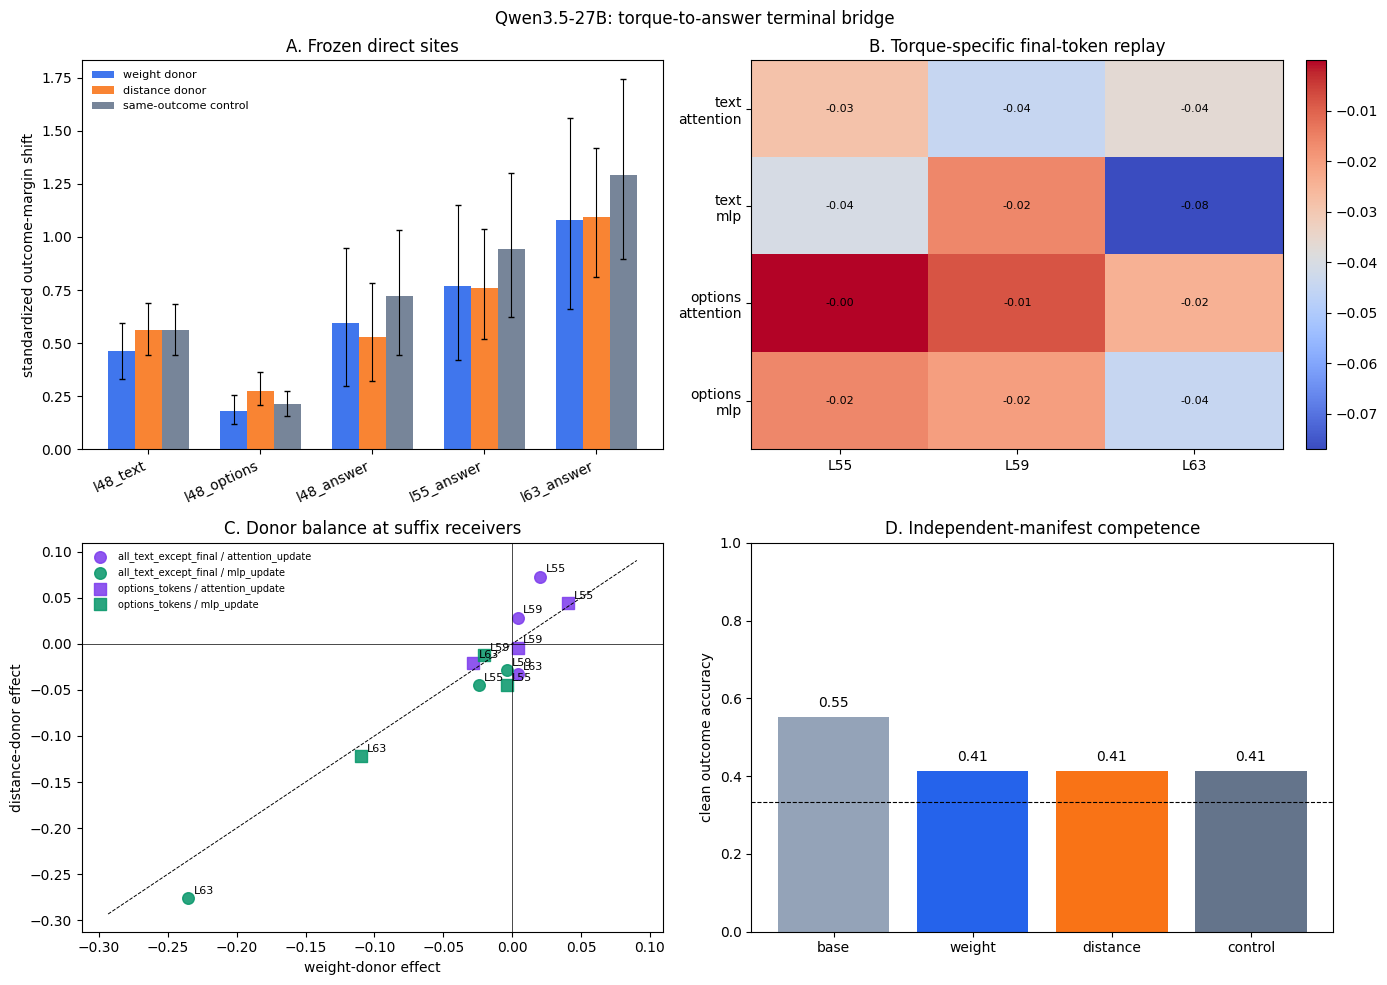

Saved: /content/drive/MyDrive/VisualTorque/results/qwen27b_torque_to_answer_bridge_v1/models/Qwen__Qwen3.5-27B__373612cb/analysis/figures/qwen27b_torque_to_answer_bridge.png


In [16]:
%%cell_progress 15/17 Save paper-facing terminal-bridge figures
cell_stage('Rendering direct effects, suffix paths, and behavior support')

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ax = axes[0, 0]
site_order = ['l48_text', 'l48_options', 'l48_answer', 'l55_answer', 'l63_answer']
x = np.arange(len(site_order))
width = 0.24
for offset, metric, label, color in (
    (-width, 'std_weight_effect', 'weight donor', '#2563eb'),
    (0, 'std_distance_effect', 'distance donor', '#f97316'),
    (width, 'std_control_effect', 'same-outcome control', '#64748b'),
):
    rows = [direct_test(site, metric) for site in site_order]
    means = np.asarray([row['mean'] for row in rows], dtype=float)
    lows = np.asarray([row['ci_low'] for row in rows], dtype=float)
    highs = np.asarray([row['ci_high'] for row in rows], dtype=float)
    ax.bar(x + offset, means, width, label=label, color=color, alpha=.88)
    ax.errorbar(
        x + offset, means, yerr=np.vstack([means - lows, highs - means]),
        fmt='none', color='black', capsize=2, linewidth=.8,
    )
ax.axhline(0, color='black', linewidth=.7)
ax.set_xticks(x, site_order, rotation=25, ha='right')
ax.set_ylabel('standardized outcome-margin shift')
ax.set_title('A. Frozen direct sites')
ax.legend(frameon=False, fontsize=8)

ax = axes[0, 1]
primary = bridge_tests[
    (bridge_tests['scope'] == 'final_prompt_token')
    & (bridge_tests['metric'] == 'std_min_physical_minus_control')
].copy()
if primary.empty:
    rows = []
    for keys, subset in bridge_frame[
        bridge_frame['scope'] == 'final_prompt_token'
    ].groupby(['source_scope', 'receiver_layer', 'component_type']):
        rows.append({
            'source_scope': keys[0], 'receiver_layer': keys[1],
            'component_type': keys[2],
            'mean': float(subset['std_min_physical_minus_control'].mean()),
        })
    primary = pd.DataFrame(rows)
labels = [
    f"{scope.replace('_tokens', '').replace('all_text_except_final', 'text')}\n{component.replace('_update', '')}"
    for scope in SOURCE_SCOPES for component in COMPONENT_TYPES
]
matrix = np.full((len(labels), len(RECEIVER_LAYERS)), np.nan)
for row_index, source_scope in enumerate(SOURCE_SCOPES):
    for component_index, component_type in enumerate(COMPONENT_TYPES):
        target_row = row_index * len(COMPONENT_TYPES) + component_index
        for column, receiver_layer in enumerate(RECEIVER_LAYERS):
            subset = bridge_frame[
                (bridge_frame['source_scope'] == source_scope)
                & (bridge_frame['receiver_layer'] == receiver_layer)
                & (bridge_frame['component_type'] == component_type)
                & (bridge_frame['scope'] == 'final_prompt_token')
            ]
            matrix[target_row, column] = float(
                subset['std_min_physical_minus_control'].mean()
            )
image = ax.imshow(matrix, cmap='coolwarm', aspect='auto')
ax.set_xticks(range(len(RECEIVER_LAYERS)), [f'L{v}' for v in RECEIVER_LAYERS])
ax.set_yticks(range(len(labels)), labels)
ax.set_title('B. Torque-specific final-token replay')
for row_index in range(matrix.shape[0]):
    for column in range(matrix.shape[1]):
        ax.text(column, row_index, f'{matrix[row_index, column]:.2f}',
                ha='center', va='center', fontsize=8)
fig.colorbar(image, ax=ax, fraction=.046, pad=.04)

ax = axes[1, 0]
for source_scope, marker in zip(SOURCE_SCOPES, ('o', 's')):
    subset = bridge_frame[
        (bridge_frame['source_scope'] == source_scope)
        & (bridge_frame['scope'] == 'final_prompt_token')
    ]
    summary = subset.groupby(['receiver_layer', 'component_type'])[[
        'std_weight_effect', 'std_distance_effect'
    ]].mean().reset_index()
    for component_type, color in (
        ('attention_update', '#7c3aed'), ('mlp_update', '#059669')
    ):
        rows = summary[summary['component_type'] == component_type]
        ax.scatter(
            rows['std_weight_effect'], rows['std_distance_effect'],
            marker=marker, s=70, color=color, alpha=.85,
            label=f"{source_scope} / {component_type}",
        )
        for _, row in rows.iterrows():
            ax.annotate(
                f"L{int(row['receiver_layer'])}",
                (row['std_weight_effect'], row['std_distance_effect']),
                xytext=(4, 3), textcoords='offset points', fontsize=8,
            )
limits = ax.get_xlim() + ax.get_ylim()
lower, upper = min(limits), max(limits)
ax.plot([lower, upper], [lower, upper], '--', color='black', linewidth=.7)
ax.axhline(0, color='black', linewidth=.5)
ax.axvline(0, color='black', linewidth=.5)
ax.set_xlabel('weight-donor effect')
ax.set_ylabel('distance-donor effect')
ax.set_title('C. Donor balance at suffix receivers')
ax.legend(frameon=False, fontsize=7)

ax = axes[1, 1]
accuracy = [
    baseline_frame['base_correct'].mean(),
    baseline_frame['weight_correct'].mean(),
    baseline_frame['distance_correct'].mean(),
    baseline_frame['control_correct'].mean(),
]
bars = ax.bar(
    ['base', 'weight', 'distance', 'control'], accuracy,
    color=['#94a3b8', '#2563eb', '#f97316', '#64748b'],
)
ax.axhline(1 / 3, color='black', linestyle='--', linewidth=.8)
ax.set_ylim(0, 1)
ax.set_ylabel('clean outcome accuracy')
ax.set_title('D. Independent-manifest competence')
for bar, value in zip(bars, accuracy):
    ax.text(bar.get_x() + bar.get_width()/2, value + .025, f'{value:.2f}', ha='center')

fig.suptitle('Qwen3.5-27B: torque-to-answer terminal bridge')
fig.tight_layout()
figure_path = FIGURE_DIR / 'qwen27b_torque_to_answer_bridge.png'
fig.savefig(figure_path, dpi=180, bbox_inches='tight')
plt.show()
print('Saved:', figure_path)


In [17]:
%%cell_progress 16/17 Apply the frozen terminal-bridge decision tree
cell_stage('Classifying a complete bridge, partial bridge, readout, or non-confirmation')

any_source_gate = any(
    value['source_gate'] for value in source_gates.values()
)
any_primary_receiver_gate = bool(primary_receiver_gates['receiver_gate'].any())
any_positive_l48_route = any(
    source_gates[scope]['positive_physical_donors']
    and source_gates[scope]['equivalent_physical_donors']
    for scope in SOURCE_SCOPES
)

if complete_terminal_bridge_gate:
    decision = 'complete_terminal_bridge_confirmed'
elif bridge_gate:
    decision = 'torque_specific_suffix_bridge_without_balanced_terminal_readout'
elif any_source_gate:
    decision = 'l48_outcome_route_confirmed_but_suffix_bridge_unresolved'
elif terminal_gate:
    decision = 'balanced_terminal_readout_without_torque_specific_l48_source'
else:
    decision = 'terminal_bridge_not_confirmed'

passing_receivers = receiver_gates[
    receiver_gates['receiver_gate']
].to_dict(orient='records')
decision_payload = {
    'schema_version': 'qwen27b-terminal-bridge-decision-1.0',
    'decision': decision,
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'triplets': len(factorial_manifest),
    'manifest_sha256': sha256_file(MANIFEST_PATH),
    'claim_registry_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'capture_config_sha256': CAPTURE_SHA256,
    'prior_depth_decision': depth_decision['decision'],
    'source_gates': source_gates,
    'terminal_gate': bool(terminal_gate),
    'bridge_gate': bool(bridge_gate),
    'complete_terminal_bridge_gate': bool(complete_terminal_bridge_gate),
    'matching_bridge_scopes': matching_bridge_scopes,
    'passing_primary_receivers': [
        row for row in passing_receivers
        if row['receiver_scope'] == 'final_prompt_token'
    ],
    'passing_localization_controls': [
        row for row in passing_receivers
        if row['receiver_scope'] == 'options_tokens'
    ],
    'diagnostics': {
        'any_positive_balanced_l48_route': bool(any_positive_l48_route),
        'any_primary_receiver_gate': bool(any_primary_receiver_gate),
    },
    'limitations': [
        (
            f'The metadata-only feasibility sample contains '
            f'{len(factorial_manifest)} triplets; equivalence tests may be '
            'less precise than under the original minimum of 32.'
        ),
        'Component replay identifies a sufficient carrier under a hybrid intervention, not a unique circuit.',
        'The same-outcome control is naturally matched and can differ in residual visual properties.',
        'Only three frozen suffix receiver layers and grouped component outputs are tested.',
        'The experiment does not establish explicit arithmetic multiplication or a natural indirect effect.',
    ],
}
DECISION_PATH = ANALYSIS_DIR / 'terminal_bridge_decision.json'
write_json_atomic(DECISION_PATH, decision_payload)
print(json.dumps(decision_payload, indent=2))


Apply the frozen terminal-bridge decision tree:  88%|########8 | 15/17 [00:00<?, ?cell/s]

{
  "schema_version": "qwen27b-terminal-bridge-decision-1.0",
  "decision": "terminal_bridge_not_confirmed",
  "model_id": "Qwen/Qwen3.5-27B",
  "model_revision": "373612cb4f9288fcf550b526d86d85febedd9801",
  "triplets": 29,
  "manifest_sha256": "sha256:07646d1840855bc4a42ab7725b7bc3e708f53d57bbb2eedd387bc7a4085164bb",
  "claim_registry_sha256": "sha256:6c9a45fb59b8b17362f5fe410506d374b3ef784316da56bdd97943ee629b2a5a",
  "capture_config_sha256": "sha256:9efffa37b21b11e1ac538cca0eca5873600bc392445c018e1de18d1ece32f4f7",
  "prior_depth_decision": "depth_relocalization_recovers_balanced_composition_route",
  "source_gates": {
    "all_text_except_final": {
      "site_label": "l48_text",
      "positive_physical_donors": true,
      "equivalent_physical_donors": false,
      "torque_specific_vs_control": false,
      "source_gate": false
    },
    "options_tokens": {
      "site_label": "l48_options",
      "positive_physical_donors": true,
      "equivalent_physical_donors": true,
     

In [18]:
%%cell_progress 17/17 Export the paper claim card and readable report
cell_stage('Writing a decision-aware report with explicit interpretation limits')

interpretations = {
    'complete_terminal_bridge_confirmed': (
        'On independent outcome-flipping scenes, a torque-specific and balanced '
        'layer-48 source state is carried by at least one frozen suffix component '
        'site into a balanced layer-63 answer readout.'
    ),
    'torque_specific_suffix_bridge_without_balanced_terminal_readout': (
        'A torque-specific suffix carrier is confirmed, but weight and distance '
        'do not yet yield an equivalent terminal answer effect.'
    ),
    'l48_outcome_route_confirmed_but_suffix_bridge_unresolved': (
        'The independent scenes confirm a torque-specific layer-48 outcome route, '
        'but none of the frozen grouped suffix components individually carries it.'
    ),
    'balanced_terminal_readout_without_torque_specific_l48_source': (
        'The terminal answer state uses both physical donors, but this experiment '
        'does not separate its layer-48 source from a generic answer-label signal.'
    ),
    'terminal_bridge_not_confirmed': (
        'The frozen terminal bridge is not confirmed on the independent manifest; '
        'distributed transport, other layers, or competence limits remain possible.'
    ),
}

report_lines = [
    '# Qwen-27B torque-to-answer terminal bridge', '',
    f"- Decision: `{decision_payload['decision']}`",
    f'- Independent triplets: {len(factorial_manifest)}',
    f'- Prior scenes excluded: {len(prior_scene_ids)}',
    '- Feasibility amendment: original minimum 32, revised minimum 24; '
    f'realized n={len(factorial_manifest)} without relaxing scene/control constraints.',
    f'- L48 source gate: {any_source_gate}',
    f'- Torque-specific suffix bridge: {bridge_gate}',
    f'- Balanced L63 terminal readout: {terminal_gate}',
    f'- Complete terminal bridge: {complete_terminal_bridge_gate}',
    f"- Matching source scopes: {matching_bridge_scopes or 'none'}", '',
    '## Interpretation', '',
    interpretations[decision_payload['decision']], '',
    '## What this establishes', '',
    'The physical donors were constructed independently of model activations. '
    'Weight and distance interventions produce the same net torque and outcome, '
    'while the natural control has the same answer but a different net torque. '
    'A passing source/receiver gate therefore requires balanced physical-donor '
    'effects and superiority over the generic answer-matched control.', '',
    '## What it does not establish', '',
    'Component-output replay is a sufficiency test under a hybrid forward pass. '
    'It does not identify a unique head-level circuit, prove explicit multiplication, '
    'or rule out interactions with unpatched states.', '',
]
if complete_terminal_bridge_gate:
    report_lines.extend([
        '## Recommended next experiment', '',
        'Replicate only the passing frozen bridge sites in Gemma and then test '
        'head/channel-level necessity with ablation-plus-rescue controls.', '',
    ])
elif bridge_gate or any_source_gate:
    report_lines.extend([
        '## Recommended next experiment', '',
        'Localize the unresolved hop around the strongest fixed receiver using a '
        'narrow adjacent-layer scan; do not expand to unconstrained head search.', '',
    ])
else:
    report_lines.extend([
        '## Recommended next experiment', '',
        'Audit clean competence and intervention effect size before adding circuit '
        'resolution. The frozen null result should remain a boundary condition.', '',
    ])

REPORT_PATH = ANALYSIS_DIR / 'terminal_bridge_report.md'
REPORT_PATH.write_text('\n'.join(report_lines) + '\n', encoding='utf-8')
write_json_atomic(ANALYSIS_DIR / 'paper_claim_card.json', {
    'decision': decision_payload['decision'],
    'interpretation': interpretations[decision_payload['decision']],
    'independent_triplets': len(factorial_manifest),
    'source_gates': source_gates,
    'passing_receivers': decision_payload['passing_primary_receivers'],
    'terminal_gate': bool(terminal_gate),
    'complete_terminal_bridge': bool(complete_terminal_bridge_gate),
    'natural_scale': NATURAL_SCALE,
})
print(REPORT_PATH.read_text(encoding='utf-8'))
print('All outputs:', ANALYSIS_DIR)


Export the paper claim card and readable report:  94%|#########4| 16/17 [00:00<?, ?cell/s]

# Qwen-27B torque-to-answer terminal bridge

- Decision: `terminal_bridge_not_confirmed`
- Independent triplets: 29
- Prior scenes excluded: 144
- Feasibility amendment: original minimum 32, revised minimum 24; realized n=29 without relaxing scene/control constraints.
- L48 source gate: False
- Torque-specific suffix bridge: False
- Balanced L63 terminal readout: False
- Complete terminal bridge: False
- Matching source scopes: none

## Interpretation

The frozen terminal bridge is not confirmed on the independent manifest; distributed transport, other layers, or competence limits remain possible.

## What this establishes

The physical donors were constructed independently of model activations. Weight and distance interventions produce the same net torque and outcome, while the natural control has the same answer but a different net torque. A passing source/receiver gate therefore requires balanced physical-donor effects and superiority over the generic answer-matched control.

## Wha